# Week 1 - Retail Data Analysis

**Student Name:** Tamara Mwakisha  
**Student ID:** 660146

**Course:** DSA 2050 — Data Science Methodologies

This notebook summarizes the retail dataset and provides a descriptive first look. Run it from the repository root after installing the packages in `requirements.txt`.

## 1. Problem framing

For this assignment, I am using a small retail dataset to answer one question: **How does recorded revenue vary by month and region?** A retail manager could use this as a starting point when deciding where to look more closely at sales or stock.

Each row represents one order, identified by `OrderID`. I will compare revenue by month and region, then summarize the results with three basic KPIs. The dataset covers only three months and does not include costs, stock levels, promotions, or information about the wider market. It can show what happened in this sample, but it cannot explain why it happened or tell us which region was more profitable.

## 2. Load and inspect the dataset

The CSV is loaded with a **relative path** from the repository root. The displayed calls satisfy the required initial inspection: `df.head()`, `df.shape`, and `df.info()`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("retail.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "retail.csv was not found. Run this notebook from the repository root "
        "or place retail.csv beside the notebook."
    )
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])


In [2]:
df.head()

,OrderID,Date,CustomerID,Region,Channel,Category,Product,Quantity,UnitPrice_KES,Revenue_KES,PaymentMethod
0,ORD0001,2026-03-23,CUST032,Mombasa,In-Store,Electronics,Wireless Mouse,3,1800,5400,M-Pesa
1,ORD0002,2026-03-28,CUST005,Nairobi,In-Store,Electronics,Bluetooth Speaker,4,5200,20800,M-Pesa
2,ORD0003,2026-03-06,CUST092,Nakuru,In-Store,Electronics,Bluetooth Speaker,2,5200,10400,Cash
3,ORD0004,2026-02-05,CUST044,Kisumu,In-Store,Electronics,Keyboard,4,3200,12800,Card
4,ORD0005,2026-01-14,CUST046,Kisumu,In-Store,Electronics,Power Bank,1,3500,3500,M-Pesa


In [3]:
df.shape

(300, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   OrderID        300 non-null    str           
 1   Date           300 non-null    datetime64[us]
 2   CustomerID     300 non-null    str           
 3   Region         300 non-null    str           
 4   Channel        300 non-null    str           
 5   Category       300 non-null    str           
 6   Product        300 non-null    str           
 7   Quantity       300 non-null    int64         
 8   UnitPrice_KES  300 non-null    int64         
 9   Revenue_KES    300 non-null    int64         
 10  PaymentMethod  300 non-null    str           
dtypes: datetime64[us](1), int64(3), str(7)
memory usage: 25.9 KB


### Dataset description

- **Rows:** 300
- **Columns:** 11
- **Main data types:** `Date` is parsed as datetime; `Quantity`, `UnitPrice_KES`, and `Revenue_KES` are numeric; IDs and descriptive fields are strings.
- **What a row represents:** One transaction/order row (`OrderID`), with its customer, date, region, channel, product, quantity, unit price, and revenue.

There are 0 missing cells and 0 exact duplicate rows. Revenue equals quantity multiplied by unit price for 300 of 300 rows in this file.


## 3. Three useful KPIs

The KPIs below use recorded order revenue. A transaction is counted once per unique `OrderID`.


In [5]:
total_revenue = df["Revenue_KES"].sum()
number_of_transactions = df["OrderID"].nunique()
average_transaction_value = total_revenue / number_of_transactions

print(f"Total revenue: KES {total_revenue:,.0f}")
print(f"Number of transactions: {number_of_transactions:,}")
print(f"Average transaction value: KES {average_transaction_value:,.2f}")

Total revenue: KES 3,206,450
Number of transactions: 300
Average transaction value: KES 10,688.17


- **Total revenue — KES 3,206,450.** Calculation: sum of `Revenue_KES`. It is the total recorded sales value across the dataset.
- **Number of transactions — 300.** Calculation: distinct count of `OrderID`. It counts the unique order rows included.
- **Average transaction value — KES 10,688.17.** Calculation: total revenue divided by distinct order count. On average, each recorded order contributed this amount in revenue.


## 4. Labelled visualizations

### Monthly revenue


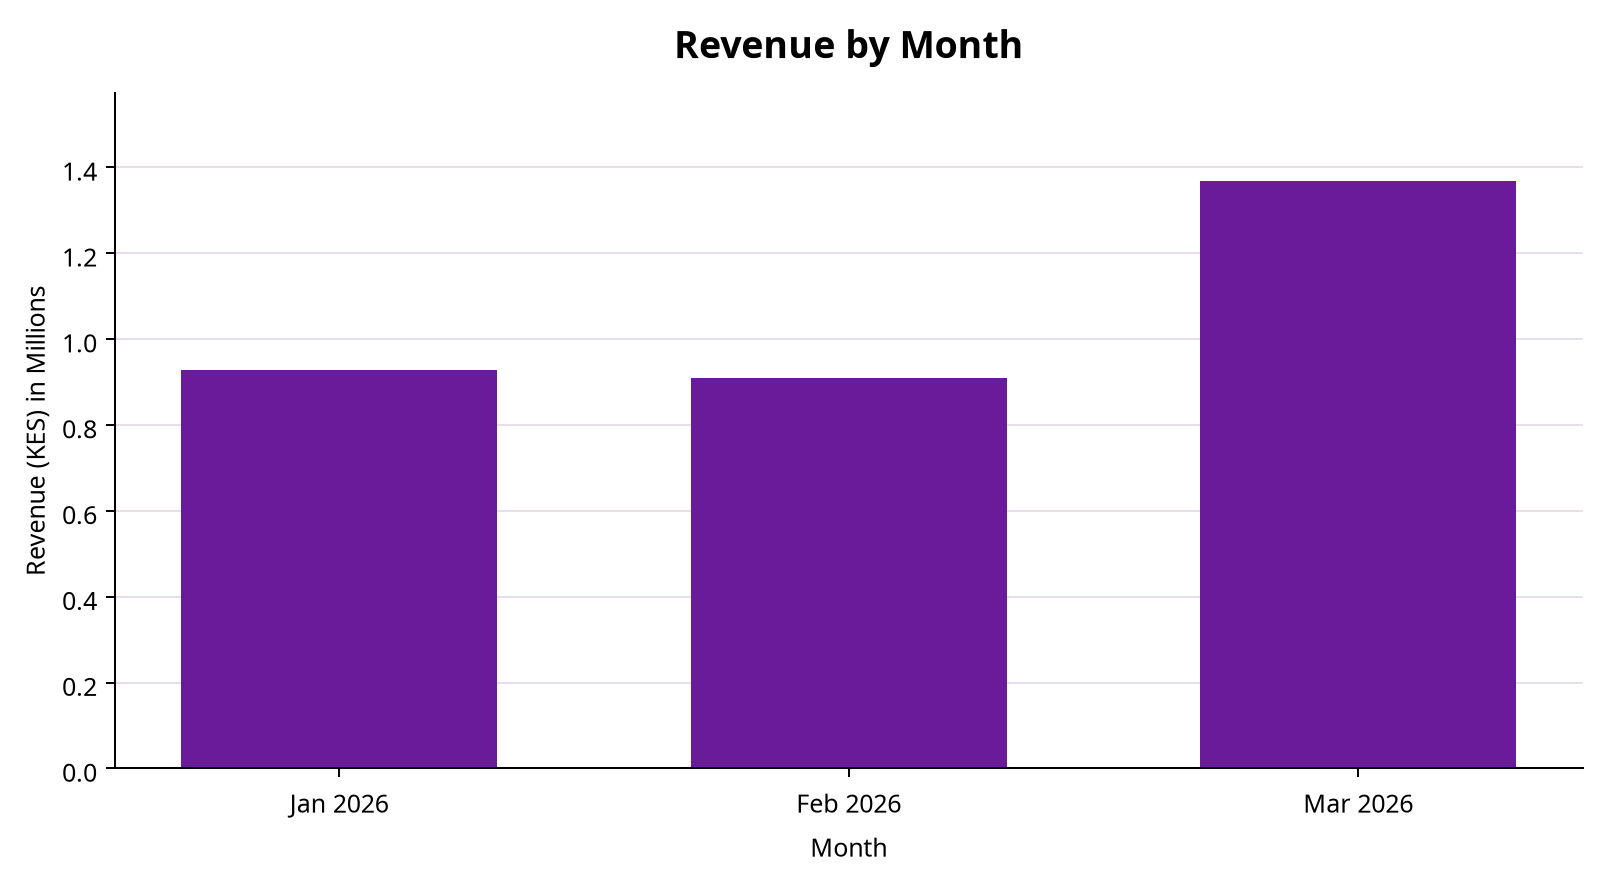

In [6]:
monthly_revenue = (
    df.assign(Month=df["Date"].dt.to_period("M").astype(str))
      .groupby("Month", sort=True)["Revenue_KES"]
      .sum()
)
month_labels = [pd.Period(month).strftime("%b %Y") for month in monthly_revenue.index]
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(month_labels, monthly_revenue.values, color="#6A1B9A", width=0.62)
ax.set_title("Revenue by Month", loc="center", fontsize=15, fontweight="bold", pad=14)
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (KES) in Millions")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1_000_000:.1f}"))
ax.set_ylim(0, max(monthly_revenue.values) * 1.15)
ax.set_axisbelow(True)
ax.grid(axis="y", color="#E7DDEB", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/monthly_revenue.png", dpi=180, bbox_inches="tight")
plt.show()

**Interpretation:** Revenue was highest in **2026-03** (KES 1,367,650) and lowest in **2026-02** (KES 909,900). The increase in the final observed month is a pattern worth reviewing, but this chart does not reveal its cause.


### Revenue by region


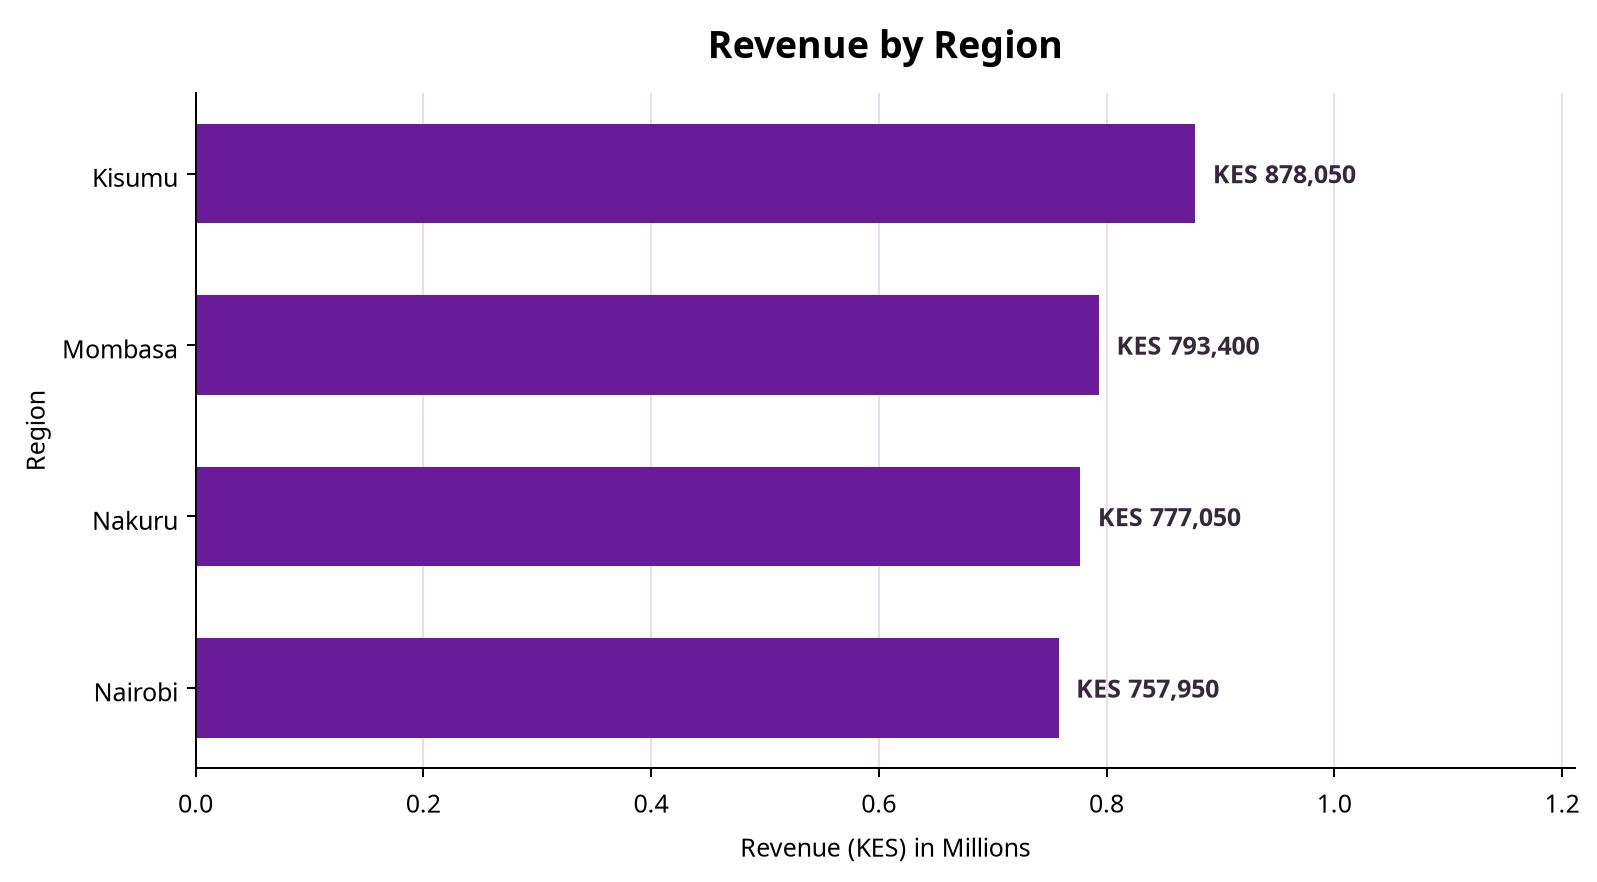

In [7]:
regional_revenue = df.groupby("Region")["Revenue_KES"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(regional_revenue.index, regional_revenue.values, color="#6A1B9A", height=0.58)
ax.invert_yaxis()
ax.set_title("Revenue by Region", loc="center", fontsize=15, fontweight="bold", pad=14)
ax.set_xlabel("Revenue (KES) in Millions")
ax.set_ylabel("Region")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1_000_000:.1f}"))
ax.set_xlim(0, max(regional_revenue.values) * 1.38)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E7DDEB", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for bar, value in zip(bars, regional_revenue.values):
    ax.annotate(f"KES {value:,.0f}",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(7, 0), textcoords="offset points", ha="left", va="center",
                fontsize=10, fontweight="bold", color="#35283B")
fig.tight_layout()
fig.savefig("outputs/revenue_by_region.png", dpi=180, bbox_inches="tight")
plt.show()

**Interpretation:** **Kisumu** generated the highest aggregate revenue (KES 878,050) in this sample. Regional totals can guide where to ask follow-up questions, but differences may reflect order mix or other unobserved factors rather than regional performance alone.


## 5. Short conclusion

The 300 order records sum to **KES 3,206,450** in revenue, with an average transaction value of **KES 10,688.17**. Monthly and regional summaries identify **2026-03** and **Kisumu** as the high points in these particular views. A sensible next step is to review product availability, order mix, and operational context for the highlighted periods/region before making resource or promotional decisions. Because the data covers only three months and lacks cost and causal context, these findings are descriptive and should not be treated as a forecast or proof of cause.
